# 06 — GARCH-X / APARCH-X cu variabile exogene

Pentru fiecare activ se estimează **toate combinațiile de câte două variabile exogene** dintre Brent, TTF, EUR/RON, USD/RON și variația ROBOR (10 combinații × 4 active = 40 modele).

- media: ARMA din `src/config.py`; volatilitatea: tipul de model ales în notebookul 05 (BET-NG, SNP: APARCH-X(1,1)-t; SNN: GARCH-X(1,1)-t; H2O: GARCH-X(1,1)-Normal);
- variabilele exogene intră în ecuația varianței ca **șocuri pătratice standardizate, decalate cu o perioadă**;
- estimare prin maximum de verosimilitate (`src/garchx.py`), 5 puncte de start;
- selecție: cel mai mic AIC pe fiecare activ (BIC raportat alături).

> **Limitare:** estimatorul propriu nu calculează erori standard, deci semnificația coeficienților exogeni nu este testată; selecția se bazează doar pe criteriile de informare.

In [1]:
import sys
import warnings
from pathlib import Path

# Face pachetul `src` importabil indiferent din ce folder se pornește notebookul
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data
from src.garchx import fit_volatility_model, prepare_inputs, residual_diagnostics

df = data.load_master_dataset()

## 1. Specificațiile de estimat

In [2]:
exogene = {nume: col for nume, col in config.EXOG_CANDIDATES.items() if col in df.columns}
perechi = list(combinations(exogene.items(), 2))

specificatii = {
    serie: {f"{serie.replace('Rand_', '')}: {n1} + {n2}": [c1, c2] for (n1, c1), (n2, c2) in perechi}
    for serie in config.ASSETS
}
nr_total = sum(len(v) for v in specificatii.values())
print("Număr total de modele de estimat:", nr_total)

Număr total de modele de estimat: 40


## 2. Estimarea tuturor combinațiilor

In [3]:
rezultate, rezumat, parametri, erori = {}, [], [], []

nr = 0
for serie, modele in specificatii.items():
    baza = config.BASE_VOLATILITY_MODEL[serie]
    dist = "t" if baza.endswith("-t") else "normal"
    tip = "APARCH-X" if baza.startswith("APARCH") else "GARCH-X"
    for nume_model, exog_cols in modele.items():
        nr += 1
        print(f"[{nr}/{nr_total}] {nume_model}")
        try:
            eps, z, _ = prepare_inputs(df, serie, exog_cols)
            fit = fit_volatility_model(tip, eps, z, dist)
        except Exception as e:
            print("   EROARE:", e)
            erori.append({"Serie": serie, "Model": nume_model, "Eroare": str(e)})
            continue

        rezultate[nume_model] = {"fit": fit, "eps": eps, "serie": serie, "exog": exog_cols, "tip": tip, "dist": dist}
        rezumat.append({"Serie": serie, "Model": nume_model, "Specificatie": f"{tip}(1,1)",
                        "Distributie": "Student-t" if dist == "t" else "Normală",
                        "Exogen_1": exog_cols[0], "Exogen_2": exog_cols[1],
                        "N_obs": fit["nobs"], "AIC": fit["aic"], "BIC": fit["bic"]})
        parametri += [{"Serie": serie, "Model": nume_model, "Parametru": k, "Estimare": v}
                      for k, v in fit["params"].items()]

rezumat, parametri, erori = pd.DataFrame(rezumat), pd.DataFrame(parametri), pd.DataFrame(erori)
print(f"Estimate cu succes: {len(rezumat)} | cu erori: {len(erori)}")

[1/40] SNP: Brent + TTF


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


[2/40] SNP: Brent + EUR/RON


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


[3/40] SNP: Brent + USD/RON


...

[39/40] BET-NG: EUR/RON + ROBOR


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


[40/40] BET-NG: USD/RON + ROBOR


c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\paulc\Downloads\bvb-energy-volatility-forecasting\bvb-energy-volatility-forecasting\.venv312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


Estimate cu succes: 40 | cu erori: 0


## 3. Modelul optim pe fiecare activ (AIC / BIC)

In [4]:
best_aic = rezumat.loc[rezumat.groupby("Serie")["AIC"].idxmin()].sort_values("Serie")
best_bic = rezumat.loc[rezumat.groupby("Serie")["BIC"].idxmin()].sort_values("Serie")

print("Cele mai bune modele după AIC:")
display(best_aic[["Model", "Specificatie", "Distributie", "AIC", "BIC"]])
print("Cele mai bune modele după BIC:")
display(best_bic[["Model", "Specificatie", "Distributie", "AIC", "BIC"]])

Cele mai bune modele după AIC:


,Model,Specificatie,Distributie,AIC,BIC
30,BET-NG: Brent + TTF,"APARCH-X(1,1)",Student-t,4690.555291,4734.816280
27,H2O: EUR/RON + USD/RON,"GARCH-X(1,1)",Normală,1648.756160,1671.277601
10,SNN: Brent + TTF,"GARCH-X(1,1)",Student-t,5967.159735,6000.355477
4,SNP: TTF + EUR/RON,"APARCH-X(1,1)",Student-t,6102.852282,6147.113271


Cele mai bune modele după BIC:


,Model,Specificatie,Distributie,AIC,BIC
30,BET-NG: Brent + TTF,"APARCH-X(1,1)",Student-t,4690.555291,4734.816280
27,H2O: EUR/RON + USD/RON,"GARCH-X(1,1)",Normală,1648.756160,1671.277601
10,SNN: Brent + TTF,"GARCH-X(1,1)",Student-t,5967.159735,6000.355477
4,SNP: TTF + EUR/RON,"APARCH-X(1,1)",Student-t,6102.852282,6147.113271


## 4. Diagnostic pe reziduurile standardizate (modelele optime după AIC)

In [5]:
ljung_rows, arch_rows = [], []
for nume_model in best_aic["Model"]:
    ljung, arch = residual_diagnostics(rezultate[nume_model]["fit"]["std_resid"])
    ljung_rows += [{"Model": nume_model, **r} for r in ljung]
    arch_rows += [{"Model": nume_model, **r} for r in arch]

diagnostic_ljung, diagnostic_arch = pd.DataFrame(ljung_rows), pd.DataFrame(arch_rows)
print("Ljung-Box:")
display(diagnostic_ljung.round(4))
print("ARCH-LM:")
display(diagnostic_arch.round(4))

Ljung-Box:


,Model,Lag,Statistica Ljung-Box,p-value,Autocorelare reziduala?
0,BET-NG: Brent + TTF,1,0.7726,0.3794,NU
1,BET-NG: Brent + TTF,5,4.6659,0.4580,NU
2,BET-NG: Brent + TTF,10,9.1032,0.5223,NU
3,BET-NG: Brent + TTF,20,15.3528,0.7559,NU
4,H2O: EUR/RON + USD/RON,1,0.0009,0.9756,NU
5,H2O: EUR/RON + USD/RON,5,6.9142,0.2271,NU
6,H2O: EUR/RON + USD/RON,10,11.4754,0.3217,NU
7,H2O: EUR/RON + USD/RON,20,24.9703,0.2026,NU
8,SNN: Brent + TTF,1,0.1118,0.7381,NU
9,SNN: Brent + TTF,5,2.3420,0.8001,NU


ARCH-LM:


,Model,Lag,Statistica ARCH-LM,p-value,Efecte ARCH reziduale?
0,BET-NG: Brent + TTF,1,0.1192,0.7299,NU
1,BET-NG: Brent + TTF,5,1.1090,0.9533,NU
2,BET-NG: Brent + TTF,10,2.7283,0.9871,NU
3,BET-NG: Brent + TTF,20,11.1473,0.9423,NU
4,H2O: EUR/RON + USD/RON,1,0.0749,0.7843,NU
5,H2O: EUR/RON + USD/RON,5,5.2624,0.3847,NU
6,H2O: EUR/RON + USD/RON,10,7.6518,0.6628,NU
7,H2O: EUR/RON + USD/RON,20,16.1875,0.7049,NU
8,SNN: Brent + TTF,1,0.5908,0.4421,NU
9,SNN: Brent + TTF,5,1.5654,0.9054,NU


## 5. Volatilitatea condiționată (modele optime)

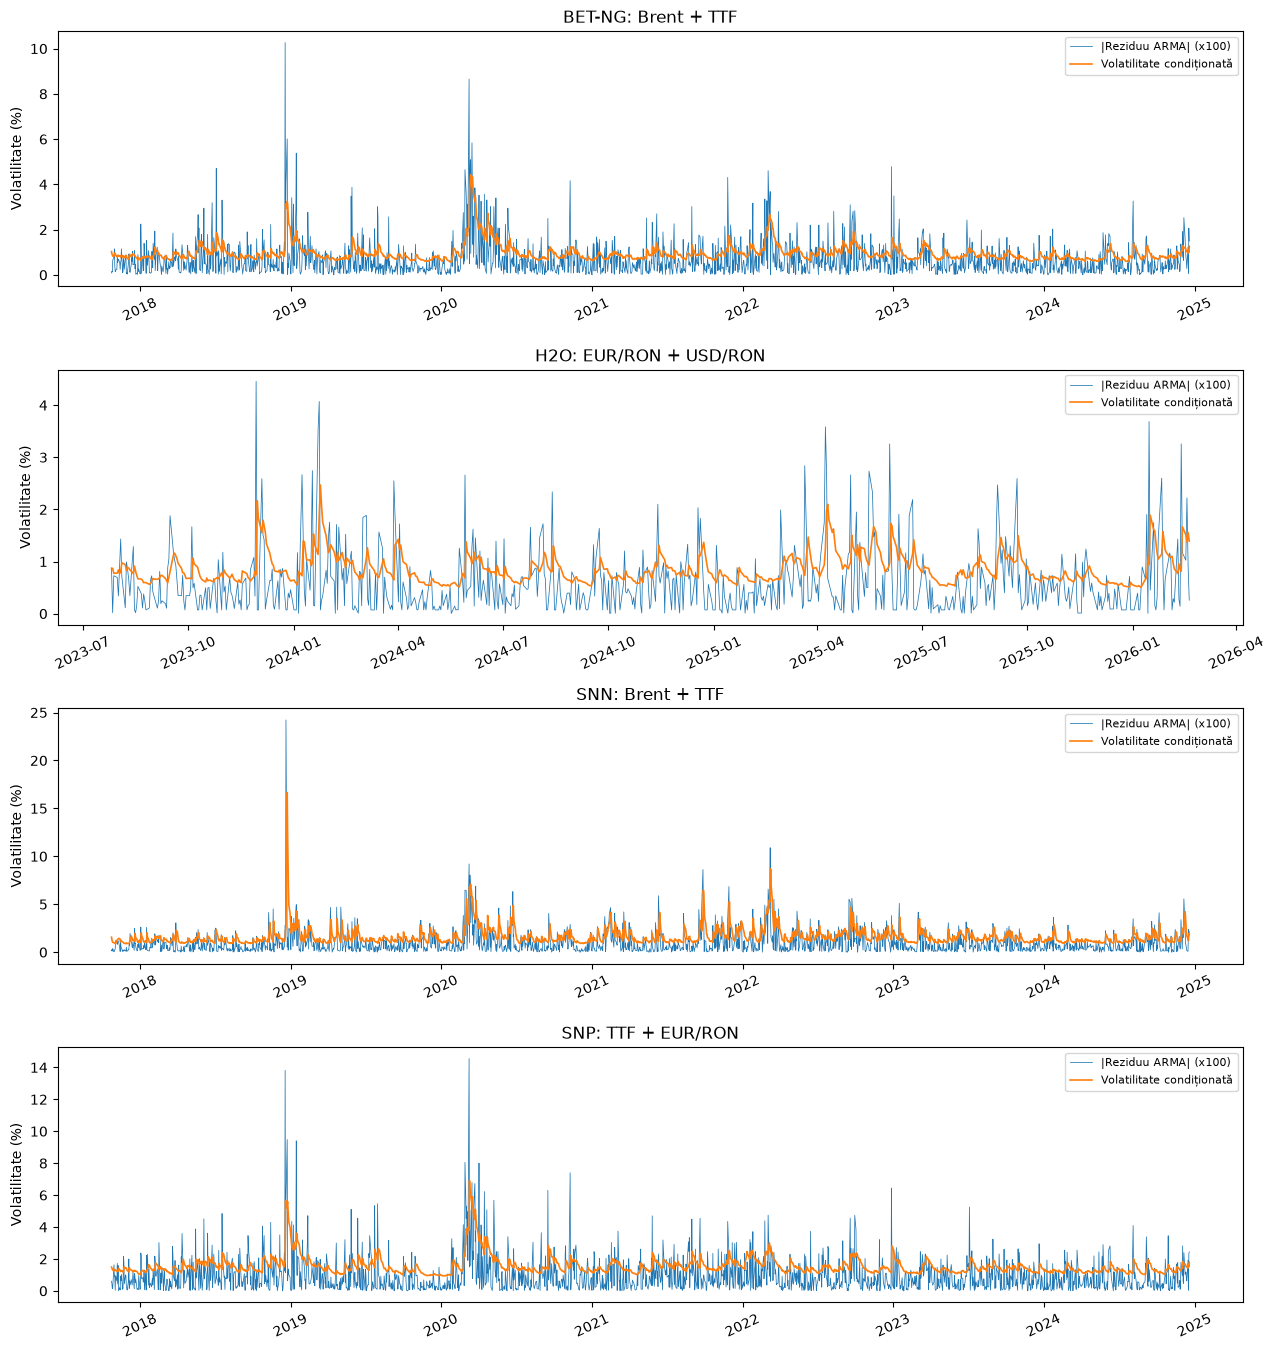

In [6]:
modele_optime = best_aic["Model"].tolist()
fig, axes = plt.subplots(len(modele_optime), 1, figsize=(13, 3.4 * len(modele_optime)))
for ax, nume in zip(np.atleast_1d(axes), modele_optime):
    obj = rezultate[nume]
    ax.plot(obj["eps"].index, np.abs(obj["eps"]), linewidth=0.55, label="|Reziduu ARMA| (x100)")
    ax.plot(obj["fit"]["sigma"].index, obj["fit"]["sigma"], linewidth=1.2, label="Volatilitate condiționată")
    ax.set_title(nume)
    ax.set_ylabel("Volatilitate (%)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "garchx_conditional_volatility.png", dpi=300, bbox_inches="tight")

## 6. Export

`garchx_optimal_models.csv` este citit de notebookul 07 (prognoze).

In [7]:
enc = "utf-8-sig"
T = config.TABLE_DIR
rezumat.to_csv(T / "garchx_all_combinations.csv", index=False, encoding=enc)
parametri.to_csv(T / "garchx_coefficients.csv", index=False, encoding=enc)
pd.concat([best_aic.assign(Criteriu="AIC minim"), best_bic.assign(Criteriu="BIC minim")], ignore_index=True) \
    .to_csv(config.GARCHX_OPTIMAL_MODELS, index=False, encoding=enc)
diagnostic_ljung.to_csv(T / "garchx_ljung_box.csv", index=False, encoding=enc)
diagnostic_arch.to_csv(T / "garchx_arch_lm.csv", index=False, encoding=enc)
if not erori.empty:
    erori.to_csv(T / "garchx_errors.csv", index=False, encoding=enc)